# Graph Transformers with GPS: mlx-graphs vs PyG

Message passing neural networks (MPNNs) such as GCN or GIN update each node from its direct neighbors. After $L$ layers, a node has only seen its $L$-hop neighborhood, so information between distant nodes needs many layers, and it gets squeezed through a few edges on the way (*over-squashing*). **Graph transformers** add global attention: every node attends to every other node of its graph in a single layer.

Attention alone ignores the graph structure, though: to a transformer, a graph is just a set of nodes. Graph transformers therefore add **positional and structural encodings** (PE/SE) to the node features, which tell the model where each node sits in the graph and what its neighborhood looks like.

**GPS** ([Rampášek et al., 2022](https://arxiv.org/abs/2205.12454)) is a recipe that combines the two ideas. Its layer runs a local MPNN and a global attention in parallel, adds their outputs, and applies an MLP, with residual connections and normalizations:

$$
\begin{aligned}
\mathbf{X}_M &= \mathrm{Norm}\big(\mathbf{X} + \mathrm{MPNN}(\mathbf{X}, \mathbf{A})\big) \\
\mathbf{X}_T &= \mathrm{Norm}\big(\mathbf{X} + \mathrm{GlobalAttn}(\mathbf{X})\big) \\
\mathbf{X}' &= \mathrm{Norm}\big(\mathbf{X}_M + \mathbf{X}_T + \mathrm{MLP}(\mathbf{X}_M + \mathbf{X}_T)\big)
\end{aligned}
$$

The MPNN keeps the inductive bias of the edges, the attention gives long-range interactions, and the PE/SE are computed once per graph and concatenated to the input features.

In this tutorial, we:

1. tour the graph-transformer datasets of mlx-graphs (`LRGBDataset`, `GNNBenchmarkDataset`);
2. compute positional and structural encodings with `AddRandomWalkPE` and `AddLaplacianEigenvectorPE`, and project them with `RWSEEncoder` and `LapPEEncoder`;
3. build a GPS model with `GPSConv` and train it on **Peptides-func**, a long-range benchmark;
4. compare the dense multi-head attention with the linear `PerformerAttention`, and compile a GPS training step with `mx.compile`;
5. train the same GPS model with PyTorch Geometric (PyG) on the same data, and compare the **average precision** (AP) and the **time per epoch**;
6. train the scalable graph transformers `SGFormer` and `Polynormer` on a node classification task.

The GPS model follows PyG's [examples/graph_gps.py](https://github.com/pyg-team/pytorch_geometric/blob/master/examples/graph_gps.py), which trains on ZINC, with 4 GPS layers instead of 10, and with the same hyperparameters in both frameworks. The PyG part needs a few extra dependencies:

`pip install torch torch_geometric pandas matplotlib`

![GPS pipeline: Peptides-func graphs from LRGBDataset get random-walk encodings (AddRandomWalkPE) and are batched 32 at a time; FeatureEncoder embeds atoms and bonds and RWSEEncoder projects the encodings; each of 4 GPSConv layers runs a local GINEConv and a global MultiheadAttention in parallel, each with a residual and BatchNorm, sums them and applies an MLP with a residual and BatchNorm; global_mean_pool and an MLP head give 10 logits, trained with binary cross-entropy, an L2 penalty and Adam with bias correction, evaluated with average precision and compared with PyG on the CPU; LapPEEncoder, PerformerAttention, DenseLayout with mx.compile, SGFormer and Polynormer are also covered](../../assets/tutorials/graph_transformers_gps.svg)

In [1]:
import time

import mlx.core as mx
import mlx.nn as nn
import mlx.optimizers as optim
import numpy as np
import pandas as pd
from mlx.utils import tree_flatten, tree_map

from mlx_graphs.datasets import GNNBenchmarkDataset, LRGBDataset, PlanetoidDataset
from mlx_graphs.loaders import Dataloader
from mlx_graphs.nn import (
    GCN,
    GINEConv,
    GPSConv,
    LapPEEncoder,
    Polynormer,
    RWSEEncoder,
    SGFormer,
)
from mlx_graphs.nn.aggr import DenseLayout
from mlx_graphs.nn.pooling import global_mean_pool
from mlx_graphs.transforms import AddLaplacianEigenvectorPE, AddRandomWalkPE
from mlx_graphs.utils import degree

# GPS hyperparameters, after PyG's examples/graph_gps.py (4 layers instead of 10)
EPOCHS = 8  # to keep the notebook short: the GPS paper trains for 200 epochs
CHANNELS = 64
PE_DIM = 8  # size of the projected encodings, out of CHANNELS
WALK_LENGTH = 20  # size of the random-walk encodings
NUM_LAYERS = 4
HEADS = 4
ATTN_DROPOUT = 0.5
BATCH_SIZE = 32
EVAL_BATCH_SIZE = 64
LR = 1e-3
WEIGHT_DECAY = 1e-5
SEED = 0

# Batches of graphs have different shapes, so MLX rarely reuses its freed
# buffers: bound its buffer cache (see the practical tips at the end).
mx.set_cache_limit(1024**3)
mx.random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.width", 200)

## Datasets for graph transformers

mlx-graphs ships the benchmarks on which graph transformers are usually evaluated. They read the same raw files as their PyG counterparts and give the same graphs, in the same order, without requiring PyTorch.

| Dataset | Class | Task | Graphs | Nodes (avg) | Download |
|---|---|---|---|---|---|
| `peptides-func` | `LRGBDataset` | 10 binary peptide functions (AP) | 15,535 | 150.9 | 30 MB |
| `peptides-struct` | `LRGBDataset` | 11 3D properties (MAE) | 15,535 | 150.9 | 30 MB |
| `PATTERN` | `GNNBenchmarkDataset` | node classification, 2 classes | 14,000 | 118.9 | 88 MB |
| `CLUSTER` | `GNNBenchmarkDataset` | node classification, 6 classes | 12,000 | 117.2 | 64 MB |
| `CSL` | `GNNBenchmarkDataset` | graph classification, 10 classes | 150 | 41 | 27 KB |

The two **Peptides** datasets of the [Long Range Graph Benchmark](https://arxiv.org/abs/2206.08164) (LRGB) are molecular graphs of peptides, chains of amino acids. A peptide's function depends on its whole shape, so the tasks need interactions between distant atoms. Node and edge features are the categorical atom and bond features of OGB (9 and 3 integers). **PATTERN** and **CLUSTER** are graphs drawn from stochastic block models, from [Benchmarking Graph Neural Networks](https://arxiv.org/abs/2003.00982). In PATTERN, the task is to find the nodes of a planted subgraph; in CLUSTER, to recover the cluster of every node from a single labelled node per cluster. We do not download them here. **CSL** is a tiny synthetic dataset that MPNNs cannot solve without positional encodings; we use it in the next section.

We load the three splits of Peptides-func. The `pre_transform` computes the random-walk structural encoding of every node once, when the dataset is first processed, and saves it with the graphs (as `random_walk_pe`). The first run downloads the data and computes the encodings, which takes a few minutes; later runs load the processed graphs from `.mlx_graphs_data/`.

In [2]:
transform = AddRandomWalkPE(WALK_LENGTH, attr_name="random_walk_pe")
datasets = {
    split: LRGBDataset("peptides-func", split, pre_transform=transform)
    for split in ["train", "val", "test"]
}
for split, dataset in datasets.items():
    print(f"{split}: {dataset}")
print(datasets["train"][0])

Loading peptides-func data ... Done
Loading peptides-func data ... Done
Loading peptides-func data ... Done
train: peptides-func(num_graphs=10873)
val: peptides-func(num_graphs=2331)
test: peptides-func(num_graphs=2331)
GraphData(
	edge_index(shape=(2, 682), int32)
	node_features(shape=(338, 9), int32)
	edge_features(shape=(682, 3), int32)
	graph_labels(shape=(1, 10), float32)
	random_walk_pe(shape=(338, 20), float32))


The global attention of GPS is dense within each graph, so its cost grows with the square of the number of nodes of the largest graph of a batch. Peptides have a few hundred atoms at most, which is small enough for full attention.

In [3]:
sizes = np.array([g.num_nodes for ds in datasets.values() for g in ds.graphs])
print(f"nodes per graph: mean {sizes.mean():.1f}, max {sizes.max()}")

nodes per graph: mean 150.9, max 444


## Positional and structural encodings

The **CSL** dataset (Circular Skip Links, [Murphy et al., 2019](https://arxiv.org/abs/1903.02541)) shows why encodings matter. Each of its 150 graphs is a cycle of 41 nodes, in which every node is also linked to the nodes $s$ steps away, for one of 10 skip lengths $s$. The class of a graph is its skip length.

In [4]:
csl = GNNBenchmarkDataset("CSL")
csl_labels = np.array([int(g.graph_labels.item()) for g in csl.graphs])
print(csl, csl[0], sep="\n")
print("nodes per graph:", {g.num_nodes for g in csl.graphs})
degrees = {int(d) for g in csl.graphs for d in np.array(degree(g.edge_index[0]))}
print("degrees:", degrees)
print("graphs per class:", np.bincount(csl_labels))

Loading CSL data ... Done
CSL(num_graphs=150)
GraphData(
	edge_index(shape=(2, 164), int32)
	graph_labels(shape=(1,), int32))
nodes per graph: {41}
degrees: {4}
graphs per class: [15 15 15 15 15 15 15 15 15 15]


All the graphs have 41 nodes of degree 4 and no node features. An MPNN starts with the same features on every node, and since all the neighborhoods look the same, every layer computes the same embedding for every node of every graph: it cannot tell the classes apart. (These graphs are indistinguishable by the 1-WL test, which bounds the power of MPNNs.)

mlx-graphs has two transforms that add encodings to the graphs. They compute them on the host with NumPy, once per graph, so they are best used as a `pre_transform`:

- `AddRandomWalkPE(k)` adds the **random-walk structural encoding** (RWSE): for every node, the probability of being back at the start after $1, \ldots, k$ steps of a random walk. It describes the neighborhood of a node (cycles, branching) and is the same for nodes with the same surroundings.
- `AddLaplacianEigenvectorPE(k)` adds the **Laplacian eigenvector positional encoding** (LapPE): the $k$ eigenvectors of the normalized graph Laplacian with the smallest non-trivial eigenvalues. They are the graph's analog of the sine waves of a sequence transformer: they give each node a coordinate.

Let's compute both on CSL.

In [5]:
rwse = AddRandomWalkPE(WALK_LENGTH)
lappe = AddLaplacianEigenvectorPE(k=4, is_undirected=True)
csl_pe = [lappe(rwse(g)) for g in csl.graphs]

first_of_class = [int(np.where(csl_labels == c)[0][0]) for c in range(10)]
rw = np.stack([np.array(csl_pe[i].random_walk_pe) for i in first_of_class])
print("std of the RWSE over the nodes of each graph:", rw.std(axis=1).max().round(6))
signatures = np.unique(rw[:, 0].round(5), axis=0)
print(f"distinct RWSE signatures: {len(signatures)} for 10 classes")
print("return probability after 1-8 steps (node 0, one graph per class):")
print(rw[:, 0, :8].round(3))

std of the RWSE over the nodes of each graph: 0.0
distinct RWSE signatures: 10 for 10 classes
return probability after 1-8 steps (node 0, one graph per class):
[[0.    0.25  0.094 0.141 0.098 0.105 0.09  0.088]
 [0.    0.25  0.    0.172 0.    0.142 0.    0.123]
 [0.    0.25  0.    0.141 0.01  0.098 0.018 0.075]
 [0.    0.25  0.    0.141 0.    0.101 0.    0.082]
 [0.    0.25  0.    0.141 0.    0.098 0.001 0.075]
 [0.    0.25  0.    0.141 0.    0.098 0.    0.075]
 [0.    0.25  0.    0.141 0.    0.098 0.004 0.075]
 [0.    0.25  0.    0.141 0.    0.098 0.    0.076]
 [0.    0.25  0.    0.141 0.02  0.098 0.03  0.075]
 [0.    0.25  0.    0.141 0.    0.098 0.003 0.075]]


All the nodes of a CSL graph have the same RWSE, because every node has the same surroundings. Across classes, however, the return probabilities differ: the skip length changes the cycles that a walk can close. With RWSE as input features, a model can classify the graphs, which an MPNN without encodings cannot. Several skip lengths only differ after a few steps, which is why the walk length matters: with 20 steps, the 10 classes have 10 distinct signatures.

LapPE, on the other hand, gives every node its own coordinates:

In [6]:
print(np.array(csl_pe[0].laplacian_eigenvector_pe[:5]).round(3))

[[-0.077  0.207 -0.023  0.22 ]
 [-0.044  0.216  0.044  0.216]
 [-0.011  0.221  0.107  0.193]
 [ 0.023  0.22   0.161  0.152]
 [ 0.056  0.214  0.199  0.096]]


### Encoders: `RWSEEncoder` and `LapPEEncoder`

A GPS model projects the encodings to a few channels and concatenates them with the embeddings of the node features. mlx-graphs provides two such projections:

- `RWSEEncoder(pe_dim, out_dim)` normalizes the RWSE (batch norm by default) and applies a linear layer. It is the `pe_norm` + `pe_lin` of PyG's GPS example.
- `LapPEEncoder(pe_dim, out_dim)` does the same for LapPE, with one extra step. An eigenvector $\mathbf{u}$ is only defined up to its sign: $-\mathbf{u}$ is just as valid, and the eigensolver picks one at random. So, during training, `LapPEEncoder` **flips the sign of every eigenvector of every graph at random** at each call, which teaches the model not to depend on it. In evaluation mode, it does not flip anything.

In [7]:
lap_encoder = LapPEEncoder(pe_dim=4, out_features_dim=PE_DIM)
pe = csl_pe[0].laplacian_eigenvector_pe

for mode in ["train", "eval"]:
    lap_encoder.train(mode == "train")
    same = mx.allclose(lap_encoder(pe), lap_encoder(pe)).item()
    print(f"{mode} mode, two calls give the same output: {same}")

rw_encoder = RWSEEncoder(WALK_LENGTH, PE_DIM)
print("projected RWSE:", rw_encoder(csl_pe[0].random_walk_pe).shape)

train mode, two calls give the same output: False
eval mode, two calls give the same output: True
projected RWSE: (41, 8)


When the encoder receives the `batch_indices` of a batch, each graph gets its own random signs. In short: use **RWSE** (`AddRandomWalkPE` + `RWSEEncoder`) when the local structure matters, as in molecules; it is cheap and needs no sign handling. Use **LapPE** (`AddLaplacianEigenvectorPE` + `LapPEEncoder`) for a global position of the nodes; it needs an eigendecomposition per graph. They can also be combined. Our Peptides-func model uses RWSE, as PyG's example.

## The GPS model in mlx-graphs

The model has four parts:

- **Input embeddings.** `FeatureEncoder` sums one `nn.Embedding` per categorical feature, as OGB's `AtomEncoder` and `BondEncoder`. Atoms are embedded into `CHANNELS - PE_DIM` channels, and the projected RWSE fill the last `PE_DIM` channels. Bonds are embedded into `CHANNELS` channels.
- **GPS layers.** Each `GPSConv` wraps a local `GINEConv`, which uses the bond embeddings, and adds a 4-head global attention with dropout 0.5 on the attention weights. Batch normalization and the MLP are built in.
- **Readout.** `global_mean_pool` averages the nodes of every graph.
- **Head.** A 3-layer MLP gives the logits of the 10 functions.

`GPSConv` lays out the nodes of each graph into a dense `[num_graphs, max_nodes, channels]` array for the attention, with a mask for the padding. The optional `layout` argument is used in the `mx.compile` section below.

In [8]:
class FeatureEncoder(nn.Module):
    """Sum of one embedding per categorical feature, initialized as
    torch.nn.Embedding (N(0, 1))."""

    def __init__(self, vocab_sizes, dims):
        super().__init__()
        self.embeddings = [nn.Embedding(size, dims) for size in vocab_sizes]
        for embedding in self.embeddings:
            embedding.weight = mx.random.normal(embedding.weight.shape)

    def __call__(self, features):
        return sum(emb(features[:, i]) for i, emb in enumerate(self.embeddings))


class GPS(nn.Module):
    def __init__(self, atom_vocab, bond_vocab, attn_type="multihead"):
        super().__init__()
        self.node_emb = FeatureEncoder(atom_vocab, CHANNELS - PE_DIM)
        self.pe_encoder = RWSEEncoder(WALK_LENGTH, PE_DIM)
        self.edge_emb = FeatureEncoder(bond_vocab, CHANNELS)
        if attn_type == "multihead":
            attn_kwargs = {"dropout": ATTN_DROPOUT}
        else:
            attn_kwargs = {"head_channels": CHANNELS // HEADS}
        self.convs = []
        for _ in range(NUM_LAYERS):
            mlp = nn.Sequential(
                nn.Linear(CHANNELS, CHANNELS), nn.ReLU(), nn.Linear(CHANNELS, CHANNELS)
            )
            self.convs.append(
                GPSConv(
                    CHANNELS,
                    GINEConv(mlp),
                    heads=HEADS,
                    attn_type=attn_type,
                    attn_kwargs=attn_kwargs,
                )
            )
        self.mlp = nn.Sequential(
            nn.Linear(CHANNELS, CHANNELS // 2),
            nn.ReLU(),
            nn.Linear(CHANNELS // 2, CHANNELS // 4),
            nn.ReLU(),
            nn.Linear(CHANNELS // 4, 10),
        )

    def __call__(
        self, node_features, pe, edge_index, edge_features, batch_indices, num_graphs,
        layout=None,
    ):  # fmt: skip
        x = mx.concatenate([self.node_emb(node_features), self.pe_encoder(pe)], 1)
        edge_features = self.edge_emb(edge_features)
        for conv in self.convs:
            x = conv(edge_index, x, batch_indices, layout, edge_features=edge_features)
        x = global_mean_pool(x, batch_indices, num_graphs)
        return self.mlp(x)


def inputs(batch):
    return (
        batch.node_features,
        batch.random_walk_pe,
        batch.edge_index,
        batch.edge_features,
        batch.batch_indices,
        batch.num_graphs,
    )


def vocab_sizes(attr):
    """Number of categories of every column of a categorical feature."""
    graphs = [g for ds in datasets.values() for g in ds.graphs]
    return (np.max([np.array(getattr(g, attr)).max(0) for g in graphs], 0) + 1).tolist()


atom_vocab, bond_vocab = vocab_sizes("node_features"), vocab_sizes("edge_features")
mlx_model = GPS(atom_vocab, bond_vocab)
mx.eval(mlx_model.parameters())
num_params = sum(v.size for _, v in tree_flatten(mlx_model.trainable_parameters()))
print(f"atom vocabularies {atom_vocab}, bond vocabularies {bond_vocab}")
print(f"{num_params:,} trainable parameters")

atom vocabularies [17, 3, 7, 7, 5, 1, 6, 2, 2], bond vocabularies [4, 1, 2]
173,914 trainable parameters


## Training with mlx-graphs

Peptides-func is a multi-label task: each peptide can have several of the 10 functions. The loss is the binary cross-entropy of the 10 logits, and the metric is the **average precision** (AP) of every function, averaged over the functions, as in OGB and LRGB.

Two details matter when porting PyG training code to MLX:

- `torch.optim.Adam` corrects the bias of its moment estimates, which are initialized at zero. `mlx.optimizers.Adam` does not by default: pass `bias_correction=True` to get the same update rule. Without it, the first updates are about 3 times larger, as the cell below shows.
- `torch.optim.Adam(weight_decay=...)` adds an L2 penalty to the gradients. With MLX, we add it to the gradients ourselves.

In [9]:
grad = {"w": mx.array([0.1])}
for bias_correction in [False, True]:
    opt = optim.Adam(learning_rate=1e-3, bias_correction=bias_correction)
    params = {"w": mx.array([1.0])}
    steps = []
    for _ in range(3):
        new = opt.apply_gradients(grad, params)
        steps.append(f"{(params['w'] - new['w']).item():.2e}")
        params = new
    print(f"bias_correction={bias_correction}: first updates {steps}")

bias_correction=False: first updates ['3.16e-03', '4.25e-03', '4.95e-03']
bias_correction=True: first updates ['1.00e-03', '1.00e-03', '1.00e-03']


The training loop computes the loss and its gradients with `nn.value_and_grad`, adds the L2 penalty, and updates the weights. `mx.eval` then runs the lazy computation of the step. We time the training and the evaluation (on the validation and test sets) separately. We train for 8 epochs only, to keep the whole notebook under 20 minutes; the GPS paper trains for 200 epochs.

In [10]:
def average_precision(labels, scores):
    """Mean over tasks of the average precision (as OGB / LRGB's eval_ap),
    skipping tasks without both positive and negative labels."""
    aps = []
    for task in range(labels.shape[1]):
        y, s = labels[:, task], scores[:, task]
        if y.min() == y.max():
            continue
        y = y[np.argsort(-s, kind="stable")]
        precision = np.cumsum(y) / np.arange(1, y.size + 1)
        aps.append((precision * y).sum() / y.sum())
    return float(np.mean(aps))


def mlx_loss_fn(model, batch):
    logits = model(*inputs(batch))
    return nn.losses.binary_cross_entropy(
        logits, batch.graph_labels, with_logits=True, reduction="mean"
    )


def mlx_train_epoch(model, optimizer, loader):
    model.train()
    loss_and_grad = nn.value_and_grad(model, mlx_loss_fn)
    total_loss, total_graphs = 0.0, 0
    for batch in loader:
        loss, grads = loss_and_grad(model, batch)
        grads = tree_map(
            lambda g, p: g + WEIGHT_DECAY * p, grads, model.trainable_parameters()
        )
        optimizer.update(model, grads)
        mx.eval(model.parameters(), optimizer.state, loss)
        total_loss += loss.item() * batch.num_graphs
        total_graphs += batch.num_graphs
    return total_loss / total_graphs


def mlx_evaluate(model, loader):
    model.eval()
    labels, scores = [], []
    for batch in loader:
        scores.append(np.array(model(*inputs(batch))))
        labels.append(np.array(batch.graph_labels))
    return average_precision(np.concatenate(labels), np.concatenate(scores))


def run_epochs(train_epoch, evaluate):
    history = []
    for epoch in range(1, EPOCHS + 1):
        start = time.perf_counter()
        loss = train_epoch()
        train_s = time.perf_counter() - start
        start = time.perf_counter()
        val_ap, test_ap = evaluate()
        eval_s = time.perf_counter() - start
        history.append(
            dict(epoch=epoch, loss=loss, val_ap=val_ap, test_ap=test_ap,
                 train_s=train_s, eval_s=eval_s)
        )  # fmt: skip
        print(
            f"Epoch {epoch:02d}  loss {loss:.4f}  val AP {val_ap:.4f}  "
            f"test AP {test_ap:.4f}  train {train_s:.1f} s  eval {eval_s:.1f} s"
        )
    return history


train_loader = Dataloader(datasets["train"], BATCH_SIZE, shuffle=True)
val_loader = Dataloader(datasets["val"], EVAL_BATCH_SIZE)
test_loader = Dataloader(datasets["test"], EVAL_BATCH_SIZE)
# bias_correction=True gives the update rule of torch.optim.Adam
mlx_optimizer = optim.Adam(learning_rate=LR, bias_correction=True)

mlx_history = run_epochs(
    lambda: mlx_train_epoch(mlx_model, mlx_optimizer, train_loader),
    lambda: (mlx_evaluate(mlx_model, val_loader), mlx_evaluate(mlx_model, test_loader)),
)

Epoch 01  loss 0.4190  val AP 0.1946  test AP 0.2009  train 42.0 s  eval 4.9 s
Epoch 02  loss 0.3293  val AP 0.2845  test AP 0.2770  train 35.2 s  eval 3.9 s
Epoch 03  loss 0.3025  val AP 0.3326  test AP 0.3250  train 30.7 s  eval 3.2 s
Epoch 04  loss 0.2936  val AP 0.2530  test AP 0.2520  train 29.7 s  eval 3.5 s
Epoch 05  loss 0.2843  val AP 0.3358  test AP 0.3296  train 29.7 s  eval 3.5 s
Epoch 06  loss 0.2784  val AP 0.3462  test AP 0.3405  train 30.3 s  eval 3.6 s
Epoch 07  loss 0.2760  val AP 0.3679  test AP 0.3518  train 30.2 s  eval 3.4 s
Epoch 08  loss 0.2717  val AP 0.3700  test AP 0.3604  train 31.9 s  eval 3.9 s


PyG's example also halves the learning rate when the validation AP has not improved for 20 epochs (`ReduceLROnPlateau`). We leave it out, as it cannot trigger in 8 epochs.

Thanks to the cache limit set at the beginning, MLX keeps at most 1 GB of freed buffers for reuse:

In [11]:
print(f"MLX buffer cache: {mx.get_cache_memory() / 1024**3:.2f} GB, "
      f"peak memory: {mx.get_peak_memory() / 1024**3:.2f} GB")  # fmt: skip

MLX buffer cache: 1.00 GB, peak memory: 1.92 GB


## Attention variants: multi-head vs Performer

Before comparing with PyG, let's look at two features of `GPSConv` that matter for speed. `GPSConv` supports two global attentions, chosen with `attn_type`:

- `"multihead"` (`mlx_graphs.nn.attention.MultiheadAttention`) is the standard softmax attention. It is exact, but its cost grows with the square of the number of nodes of the largest graph in the batch.
- `"performer"` (`mlx_graphs.nn.attention.PerformerAttention`, [Choromanski et al., 2021](https://arxiv.org/abs/2009.14794)) approximates the attention with random features, which avoids the $N \times N$ attention matrix: its cost is linear in the number of nodes. Call `redraw_projection_matrix()` on the layer to draw new random features from time to time, as PyG's example does.

Let's time one `GPSConv` layer (attention only, `conv=None`, in evaluation mode) with each attention, on batches of 8,192 nodes made of graphs of increasing size, and record the peak memory of MLX.

In [12]:
def time_forward(module, *args, repeats=10):
    for _ in range(3):  # warm-up
        mx.eval(module(*args))
    start = time.perf_counter()
    for _ in range(repeats):
        mx.eval(module(*args))
    return (time.perf_counter() - start) / repeats * 1000


no_edges = mx.zeros((2, 0), dtype=mx.int32)
timings = []
for graph_size in [128, 512, 2048, 4096]:
    num_graphs = 8192 // graph_size
    batch_indices = mx.repeat(mx.arange(num_graphs), graph_size)
    x = mx.random.normal((8192, CHANNELS))
    row = {"nodes per graph": graph_size, "graphs": num_graphs}
    for attn_type, kwargs in [
        ("multihead", {}),
        ("performer", {"head_channels": CHANNELS // HEADS}),
    ]:
        layer = GPSConv(CHANNELS, None, heads=HEADS, attn_type=attn_type,
                        attn_kwargs=kwargs)  # fmt: skip
        layer.eval()
        mx.reset_peak_memory()
        milliseconds = time_forward(layer, no_edges, x, batch_indices)
        row[f"{attn_type} (ms)"] = round(milliseconds, 2)
        row[f"{attn_type} peak (MB)"] = round(mx.get_peak_memory() / 1024**2)
    timings.append(row)
pd.DataFrame(timings).set_index("nodes per graph")

,graphs,multihead (ms),multihead peak (MB),performer (ms),performer peak (MB)
nodes per graph,,,,,
128,64,2.00,396,1.78,398
512,16,2.82,444,0.92,398
2048,4,9.42,636,0.95,397
4096,2,18.43,892,0.99,397


With the same number of nodes per batch, the multi-head attention gets slower and needs more memory as the graphs grow: its cost is proportional to the sum of the squared graph sizes. The time and peak memory of the Performer stay flat. (The peak memory also counts the arrays that were already allocated, such as the datasets.) For graphs of a few hundred nodes, like the peptides, both are fast, and the exact attention is the usual choice. The Performer pays off for graphs of thousands of nodes, or when the memory of the attention is the bottleneck. Its approximation can cost some accuracy, so compare both on your task.

The Peptides-func model can switch to the Performer with `GPS(atom_vocab, bond_vocab, attn_type="performer")`.

## `mx.compile` with a precomputed layout

To run the dense attention, `GPSConv` needs to know which nodes belong to which graph, and how large the largest graph is. By default, it computes this layout from `batch_indices` **on the host**, in every layer. Reading `batch_indices` back from the GPU forces MLX to stop and evaluate the pending computation, a GPU synchronization, and it makes the layer impossible to trace with `mx.compile`, which needs functions of arrays only.

`GPSConv` (and `SGFormer` and `Polynormer`) accept a precomputed `layout`, a `DenseLayout`:

- `DenseLayout(batch_indices, num_nodes)` computes it on the host, once per batch instead of once per layer;
- `DenseLayout.from_sizes(batch_indices, num_nodes, num_graphs, max_num_nodes)` builds it **on the device**, from the number of graphs and an upper bound of the graph size. There is no synchronization, and it works inside `mx.compile`.

A larger `max_num_nodes` only adds padding, which the masked multi-head attention ignores, so the outputs are the same, up to floating-point rounding:

In [13]:
batch = next(iter(Dataloader(datasets["train"], BATCH_SIZE)))
num_nodes, num_graphs = batch.num_nodes, batch.num_graphs
max_num_nodes = int(sizes.max())  # largest peptide of the dataset
layout = DenseLayout.from_sizes(
    batch.batch_indices, num_nodes, num_graphs, max_num_nodes
)
mlx_model.eval()
default_out = mlx_model(*inputs(batch))
layout_out = mlx_model(*inputs(batch), layout=layout)
difference = mx.abs(default_out - layout_out).max().item()
print(f"largest difference between the logits: {difference:.1e}")

largest difference between the logits: 0.0e+00


Now let's compile a full training step: forward, backward, L2 penalty and Adam update. The model, the optimizer state and the random state (for the dropout) are passed to `mx.compile` as implicit inputs and outputs. We time four versions of the step on the same batch, each with a fresh model: the default layout, a `DenseLayout` built once per batch on the host, a layout built from sizes on the device, and the same compiled. The bound `max_num_nodes` is the size of the largest peptide of the dataset, so that this layout is valid for any batch of 32 graphs.

In [14]:
from functools import partial


def make_step(model, optimizer, layout_type, compiled=False):
    def loss_fn(model, x, pe, edge_index, edge_features, batch_indices, labels):
        layout = None  # default: computed on the host by every layer
        if layout_type == "host":  # on the host, once per batch
            layout = DenseLayout(batch_indices, x.shape[0])
        elif layout_type == "sizes":  # on the device, from constant sizes
            layout = DenseLayout.from_sizes(
                batch_indices, x.shape[0], num_graphs, max_num_nodes
            )
        logits = model(x, pe, edge_index, edge_features, batch_indices, num_graphs,
                       layout)  # fmt: skip
        return nn.losses.binary_cross_entropy(logits, labels, with_logits=True)

    loss_and_grad = nn.value_and_grad(model, loss_fn)

    def step(*arrays):
        loss, grads = loss_and_grad(model, *arrays)
        grads = tree_map(
            lambda g, p: g + WEIGHT_DECAY * p, grads, model.trainable_parameters()
        )
        optimizer.update(model, grads)
        return loss

    if compiled:
        state = [model.state, optimizer.state, mx.random.state]
        step = partial(mx.compile, inputs=state, outputs=state)(step)
    return step


arrays = (
    batch.node_features,
    batch.random_walk_pe,
    batch.edge_index,
    batch.edge_features,
    batch.batch_indices,
    batch.graph_labels,
)
step_times = {}
for label, layout_type, compiled in [
    ("default (layout in every layer)", None, False),
    ("DenseLayout once per batch", "host", False),
    ("DenseLayout.from_sizes", "sizes", False),
    ("DenseLayout.from_sizes + mx.compile", "sizes", True),
]:
    mx.random.seed(SEED)
    model = GPS(atom_vocab, bond_vocab)
    optimizer = optim.Adam(learning_rate=LR, bias_correction=True)
    model.train()
    step = make_step(model, optimizer, layout_type, compiled)
    for _ in range(3):  # warm-up (and compilation)
        mx.eval(step(*arrays), model.parameters(), optimizer.state)
    start = time.perf_counter()
    for _ in range(20):
        mx.eval(step(*arrays), model.parameters(), optimizer.state)
    step_times[label] = (time.perf_counter() - start) / 20 * 1000
    print(f"{label:36s} {step_times[label]:6.1f} ms per step")

default (layout in every layer)        78.0 ms per step
DenseLayout once per batch             76.7 ms per step
DenseLayout.from_sizes                 97.6 ms per step
DenseLayout.from_sizes + mx.compile    72.8 ms per step


Building the layout once per batch instead of in every layer changes little here, because the step is dominated by the work on the GPU. The layout from sizes alone is slower: the dense arrays are padded to the largest peptide of the dataset instead of the largest graph of the batch, so the attention does more work. Compiling the step makes it the fastest of the four (see the times printed above): `mx.compile` fuses the elementwise operations of the step into fewer GPU kernels, and skips the construction of the computation graph at every call.

One caveat: `mx.compile` traces the function for the shapes it receives. Every batch of Peptides-func has a different number of nodes and edges, so a compiled step would be traced again for almost every batch, which costs more than it saves. To benefit from compilation in a full training loop, pad the batches to a few fixed sizes (buckets), so that the same compiled graphs are reused.

## The same model in PyG

The PyG version uses PyG's own `GPSConv`, `GINEConv` and `global_mean_pool`, with the same architecture and hyperparameters. To train both frameworks on exactly the same data, we convert the mlx-graphs graphs, with their RWSE, into PyG `Data` objects. (PyG's `LRGBDataset` with the `AddRandomWalkPE` transform gives the same graphs and encodings.)

PyG runs on the CPU here. PyG's `GPSConv` relies on many small indexing and scatter operations, for which the CPU is a better choice than the MPS backend.

In [15]:
import torch
from torch.nn import BatchNorm1d, Embedding, Linear, ModuleList, ReLU, Sequential
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader as PyGDataLoader
from torch_geometric.nn import GINEConv as PyGGINEConv
from torch_geometric.nn import GPSConv as PyGGPSConv
from torch_geometric.nn import global_mean_pool as pyg_global_mean_pool

torch.manual_seed(SEED)
# Release the buffers that MLX keeps for reuse, for PyTorch to use them.
mx.clear_cache()


def to_pyg(dataset):
    def tensor(array, dtype):
        return torch.from_numpy(np.array(array)).to(dtype)

    return [
        Data(
            x=tensor(g.node_features, torch.long),
            edge_index=tensor(g.edge_index, torch.long),
            edge_attr=tensor(g.edge_features, torch.long),
            y=tensor(g.graph_labels, torch.float),
            pe=tensor(g.random_walk_pe, torch.float),
        )
        for g in dataset
    ]


pyg_data = {split: to_pyg(dataset) for split, dataset in datasets.items()}
print(pyg_data["train"][0])

Data(x=[338, 9], edge_index=[2, 682], edge_attr=[682, 3], y=[1, 10], pe=[338, 20])


In [16]:
class PyGFeatureEncoder(torch.nn.Module):
    def __init__(self, vocab_sizes, dims):
        super().__init__()
        self.embeddings = ModuleList([Embedding(v, dims) for v in vocab_sizes])

    def forward(self, features):
        return sum(emb(features[:, i]) for i, emb in enumerate(self.embeddings))


class PyGGPS(torch.nn.Module):
    def __init__(self, atom_vocab, bond_vocab):
        super().__init__()
        self.node_emb = PyGFeatureEncoder(atom_vocab, CHANNELS - PE_DIM)
        self.pe_norm = BatchNorm1d(WALK_LENGTH)
        self.pe_lin = Linear(WALK_LENGTH, PE_DIM)
        self.edge_emb = PyGFeatureEncoder(bond_vocab, CHANNELS)
        self.convs = ModuleList()
        for _ in range(NUM_LAYERS):
            mlp = Sequential(
                Linear(CHANNELS, CHANNELS), ReLU(), Linear(CHANNELS, CHANNELS)
            )
            conv = PyGGPSConv(
                CHANNELS,
                PyGGINEConv(mlp),
                heads=HEADS,
                attn_type="multihead",
                attn_kwargs={"dropout": ATTN_DROPOUT},
            )
            self.convs.append(conv)
        self.mlp = Sequential(
            Linear(CHANNELS, CHANNELS // 2),
            ReLU(),
            Linear(CHANNELS // 2, CHANNELS // 4),
            ReLU(),
            Linear(CHANNELS // 4, 10),
        )

    def forward(self, x, pe, edge_index, edge_attr, batch):
        x = torch.cat([self.node_emb(x), self.pe_lin(self.pe_norm(pe))], 1)
        edge_attr = self.edge_emb(edge_attr)
        for conv in self.convs:
            x = conv(x, edge_index, batch, edge_attr=edge_attr)
        return self.mlp(pyg_global_mean_pool(x, batch))


pyg_model = PyGGPS(atom_vocab, bond_vocab)
pyg_params = sum(p.numel() for p in pyg_model.parameters())
print(f"{pyg_params:,} trainable parameters (mlx-graphs: {num_params:,})")

173,914 trainable parameters (mlx-graphs: 173,914)


Both models have the same number of trainable parameters. The training loop is the usual PyG one.

In [17]:
pyg_optimizer = torch.optim.Adam(
    pyg_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY
)
criterion = torch.nn.BCEWithLogitsLoss()
pyg_train_loader = PyGDataLoader(pyg_data["train"], BATCH_SIZE, shuffle=True)
pyg_val_loader = PyGDataLoader(pyg_data["val"], EVAL_BATCH_SIZE)
pyg_test_loader = PyGDataLoader(pyg_data["test"], EVAL_BATCH_SIZE)


def pyg_train_epoch():
    pyg_model.train()
    total_loss, total_graphs = 0.0, 0
    for data in pyg_train_loader:
        pyg_optimizer.zero_grad()
        out = pyg_model(data.x, data.pe, data.edge_index, data.edge_attr, data.batch)
        loss = criterion(out, data.y)
        loss.backward()
        pyg_optimizer.step()
        total_loss += loss.item() * data.num_graphs
        total_graphs += data.num_graphs
    return total_loss / total_graphs


@torch.no_grad()
def pyg_evaluate(loader):
    pyg_model.eval()
    labels, scores = [], []
    for data in loader:
        out = pyg_model(data.x, data.pe, data.edge_index, data.edge_attr, data.batch)
        scores.append(out.numpy())
        labels.append(data.y.numpy())
    return average_precision(np.concatenate(labels), np.concatenate(scores))

## Training with PyG

In [18]:
print(f"PyTorch {torch.__version__}, {torch.get_num_threads()} CPU threads")
pyg_history = run_epochs(
    pyg_train_epoch,
    lambda: (pyg_evaluate(pyg_val_loader), pyg_evaluate(pyg_test_loader)),
)

PyTorch 2.15.0, 6 CPU threads
Epoch 01  loss 0.3586  val AP 0.3318  test AP 0.3248  train 79.3 s  eval 10.3 s
Epoch 02  loss 0.2875  val AP 0.3598  test AP 0.3519  train 86.8 s  eval 11.3 s
Epoch 03  loss 0.2775  val AP 0.3654  test AP 0.3502  train 82.8 s  eval 10.0 s
Epoch 04  loss 0.2717  val AP 0.3777  test AP 0.3686  train 79.2 s  eval 9.0 s
Epoch 05  loss 0.2676  val AP 0.3622  test AP 0.3514  train 77.3 s  eval 8.4 s
Epoch 06  loss 0.2640  val AP 0.3944  test AP 0.3776  train 76.1 s  eval 8.3 s
Epoch 07  loss 0.2620  val AP 0.3322  test AP 0.3352  train 75.3 s  eval 8.1 s
Epoch 08  loss 0.2586  val AP 0.3880  test AP 0.3734  train 76.6 s  eval 8.4 s


## Comparison

The table below summarizes the two runs: the best validation AP, the test AP at the epoch of the best validation AP (the usual model selection), and the median time per epoch for training and for evaluation (the median is less sensitive than the mean to an epoch slowed down by other programs).

In [19]:
rows = []
for name, history in [("mlx-graphs", mlx_history), ("PyG", pyg_history)]:
    best = max(history, key=lambda h: h["val_ap"])
    rows.append(
        {
            "framework": name,
            "best val AP": round(best["val_ap"], 4),
            "test AP (best val)": round(best["test_ap"], 4),
            "best epoch": best["epoch"],
            "train s/epoch": round(np.median([h["train_s"] for h in history]), 1),
            "eval s/epoch": round(np.median([h["eval_s"] for h in history]), 1),
        }
    )
summary = pd.DataFrame(rows).set_index("framework")
summary

,best val AP,test AP (best val),best epoch,train s/epoch,eval s/epoch
framework,,,,,
mlx-graphs,0.3700,0.3604,8,30.5,3.6
PyG,0.3944,0.3776,6,78.2,8.7


In [20]:
speedup_train = (
    summary.loc["PyG", "train s/epoch"] / summary.loc["mlx-graphs", "train s/epoch"]
)
speedup_eval = (
    summary.loc["PyG", "eval s/epoch"] / summary.loc["mlx-graphs", "eval s/epoch"]
)
print(
    f"mlx-graphs trains {speedup_train:.1f}x faster and evaluates "
    f"{speedup_eval:.1f}x faster than PyG."
)

mlx-graphs trains 2.6x faster and evaluates 2.4x faster than PyG.


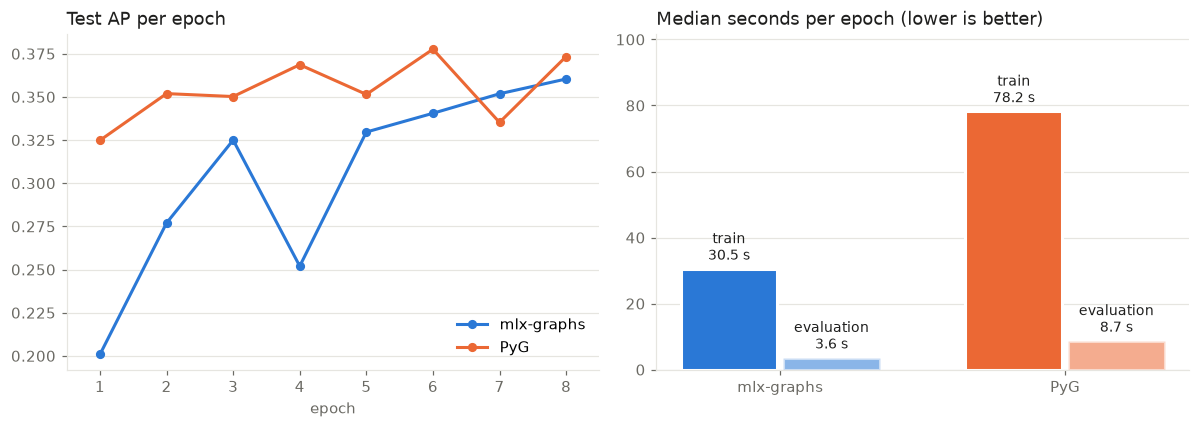

In [21]:
import matplotlib.pyplot as plt

COLORS = {"mlx-graphs": "#2a78d6", "PyG": "#eb6834"}
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e6e5e0"

fig, (ax_ap, ax_time) = plt.subplots(1, 2, figsize=(11, 4))
epochs = np.arange(1, EPOCHS + 1)

for name, history in [("mlx-graphs", mlx_history), ("PyG", pyg_history)]:
    ap = [h["test_ap"] for h in history]
    ax_ap.plot(epochs, ap, color=COLORS[name], linewidth=2, marker="o",
               markersize=5, label=name)  # fmt: skip

names = ["mlx-graphs", "PyG"]
x = np.arange(2)
width = 0.36
for offset, column, label, alpha in [
    (-width / 2, "train s/epoch", "train", 1.0),
    (width / 2, "eval s/epoch", "evaluation", 0.55),
]:
    values = [summary.loc[n, column] for n in names]
    bars = ax_time.bar(x + offset, values, width - 0.02, alpha=alpha,
                       color=[COLORS[n] for n in names], edgecolor="white",
                       linewidth=2)  # fmt: skip
    for bar, value in zip(bars, values):
        ax_time.annotate(f"{label}\n{value:.1f} s",
                         (bar.get_x() + bar.get_width() / 2, value),
                         xytext=(0, 3), textcoords="offset points", ha="center",
                         va="bottom", color=INK, fontsize=9)  # fmt: skip

ax_ap.set_title("Test AP per epoch", loc="left", color=INK)
ax_ap.set_xlabel("epoch", color=MUTED)
ax_ap.set_xticks(epochs)
ax_ap.set_xlim(0.5, EPOCHS + 0.5)
ax_ap.legend(frameon=False, loc="lower right")
ax_time.set_title("Median seconds per epoch (lower is better)", loc="left", color=INK)
ax_time.set_xticks(x, names)
ax_time.set_ylim(0, max(summary["train s/epoch"]) * 1.3)
for ax in (ax_ap, ax_time):
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
fig.tight_layout()
plt.show()

**Accuracy.** After 8 epochs, both models are early in their training: the test AP is still rising, and it jumps from one epoch to the next, as does the validation AP used to select the model. The two frameworks end in the same range, and the gap between them is of the order of these fluctuations. The mlx-graphs run is also not exactly reproducible on the GPU, so two runs with the same seed differ slightly. Comparing final accuracies would need a much longer training: the GPS paper trains for 200 epochs. For an exact check, `benchmarks/gps_peptides/grad_parity.py` in the mlx-graphs repository copies the weights of the PyG model into the mlx-graphs model, and finds the same loss and the same gradients, up to the precision of GPU matrix products.

**Runtime.** These timings were measured on an Apple M5 Pro, with mlx-graphs on the GPU and PyG on the CPU (6 threads). mlx-graphs is faster than PyG at both training and evaluation (see the speedups printed above). Timings vary from run to run and from machine to machine, so run the notebook on your own machine to compare.

## Scalable graph transformers: SGFormer and Polynormer

GPS attends over all the nodes of each graph, which suits many small graphs. For node classification on one large graph, quadratic attention is out of reach, and mlx-graphs provides two models with **linear** global attention, as PyG:

- `SGFormer` ([Wu et al., 2023](https://arxiv.org/abs/2306.10759)) adds a single linear attention branch (`SGFormerAttention`) to a GCN branch, and combines them with a weight `graph_weight`.
- `Polynormer` ([Deng et al., 2024](https://arxiv.org/abs/2403.01232)) stacks local layers (GCN, or GAT with `local_attn=True`) and global linear attention layers (`PolynormerAttention`) that build polynomial functions of the input features. It is trained in two phases: the local layers first, then the global layers, enabled with `model._global = True`.

Both take `(edge_index, node_features)` and return log-probabilities per node. We train them on Cora (2,708 papers, 7 classes, 140 training labels), with a GCN as a baseline, and report the test accuracy at the epoch of the best validation accuracy.

In [22]:
cora = PlanetoidDataset("cora")[0]
labels = cora.node_labels
split_idx = {
    name: mx.array(np.where(np.array(getattr(cora, f"{name}_mask")))[0])
    for name in ["train", "val", "test"]
}


def accuracy(model, split):
    pred = model(cora.edge_index, cora.node_features).argmax(-1)
    return (pred[split_idx[split]] == labels[split_idx[split]]).mean().item()


def train_node_classifier(model, epochs=200, warmup=None, lr=0.01, wd=5e-4):
    optimizer = optim.Adam(learning_rate=lr, bias_correction=True)
    idx = split_idx["train"]

    def loss_fn(model):
        # SGFormer and Polynormer return log-probabilities, the GCN logits:
        # log_softmax gives log-probabilities in both cases
        log_probs = nn.log_softmax(model(cora.edge_index, cora.node_features)[idx])
        return -mx.take_along_axis(log_probs, labels[idx, None], 1).mean()

    loss_and_grad = nn.value_and_grad(model, loss_fn)
    global_part = []
    if warmup is not None:  # Polynormer: train the local layers first
        global_part = [*model.global_attn, model.ln, model.pred_global]
        for module in global_part:
            module.freeze()
    best_val, best_test, start = 0.0, 0.0, time.perf_counter()
    for epoch in range(epochs):
        if epoch == warmup:  # then enable the global attention
            model._global = True
            for module in global_part:
                module.unfreeze()
            optimizer.init(model.trainable_parameters())
        model.train()
        loss, grads = loss_and_grad(model)
        grads = tree_map(lambda g, p: g + wd * p, grads, model.trainable_parameters())
        optimizer.update(model, grads)
        mx.eval(model.parameters(), optimizer.state)
        model.eval()
        val_acc = accuracy(model, "val")
        if val_acc > best_val:
            best_val, best_test = val_acc, accuracy(model, "test")
    return dict(val_acc=round(best_val, 3), test_acc=round(best_test, 3),
                seconds=round(time.perf_counter() - start, 1))  # fmt: skip


num_features, num_classes = cora.node_features.shape[1], 7
results = {}
mx.random.seed(SEED)
gcn = GCN(num_features, 64, 2, num_classes, dropout=0.5)
results["GCN"] = train_node_classifier(gcn)
mx.random.seed(SEED)
results["SGFormer"] = train_node_classifier(SGFormer(num_features, 64, num_classes))
mx.random.seed(SEED)
polynormer = Polynormer(num_features, 64, num_classes, local_layers=3, global_layers=2)
results["Polynormer"] = train_node_classifier(polynormer, warmup=100)
pd.DataFrame(results).T

Loading cora data ... Done


,val_acc,test_acc,seconds
GCN,0.794,0.801,0.3
SGFormer,0.656,0.655,1.3
Polynormer,0.742,0.753,1.3


On Cora, the GCN baseline is the most accurate of the three. Cora is a small citation graph with only 140 labels, in which linked papers usually share their class: the neighbors carry most of the signal, and the global attention mostly adds parameters that can overfit. (PyG's `SGFormer` and `Polynormer` reach similar accuracies with these settings.) The two models are designed for large graphs, such as `ogbn-arxiv` or `ogbn-products`, on which their linear attention scales to millions of nodes, since it never builds an $N \times N$ matrix; the code above runs on them unchanged.

As a rule of thumb, use `GPSConv` for datasets of many small graphs, `SGFormer` for a simple scalable baseline on a large graph, and `Polynormer` for a more expressive model on a large graph, at the cost of a two-phase training.

The Polynormer warm-up shows a difference between MLX and PyTorch to keep in mind. During the warm-up, the global layers are not used. PyTorch leaves their `.grad` at `None`, and `torch.optim.Adam` skips them. MLX returns zero gradients for them instead, and an L2 penalty added to the gradients would then let Adam shrink them toward zero at every step, as if they were trained to vanish. So we `freeze()` them during the warm-up, then `unfreeze()` them and initialize their optimizer state with `optimizer.init(...)`.

## Practical tips

- **Adam.** Use `optim.Adam(..., bias_correction=True)` to get the update rule of `torch.optim.Adam`, and add `weight_decay * p` to the gradients for its L2 penalty.
- **Unused parameters.** MLX gives zero gradients to parameters that do not take part in the loss, where PyTorch skips them. Freeze such parameters if a penalty or a momentum could move them.
- **Buffer cache.** Batches of graphs have different shapes, so MLX can rarely reuse its freed buffers, and its cache can grow to many GB. Bound it with `mx.set_cache_limit(...)` (1 GB here), and release it with `mx.clear_cache()` before another framework runs in the same process.
- **Encodings.** Compute the PE/SE once, as a `pre_transform` of the dataset: they are computed on the host with NumPy and saved with the processed graphs.
- **Layouts and compilation.** Build a `DenseLayout` once per batch instead of once per layer, and use `DenseLayout.from_sizes(...)` to compile a step with `mx.compile`, with padded batch sizes.
- **Attention.** Keep `attn_type="multihead"` for graphs of up to a few thousand nodes, and switch to `"performer"`, `SGFormer` or `Polynormer` beyond.

## Going further

- [examples/graph_gps_peptides.py](https://github.com/mlx-graphs/mlx-graphs/blob/main/examples/graph_gps_peptides.py) is a command-line version of the GPS part of this tutorial, with the learning rate schedule of PyG's example. Train it for more epochs: the GPS paper trains for 200 epochs, with a tuned configuration.
- Peptides-struct uses the same graphs with 11 regression targets: load it with `LRGBDataset("peptides-struct")` and replace the loss with the mean absolute error.
- Add LapPE to the model: `Compose([AddRandomWalkPE(20), AddLaplacianEigenvectorPE(8)])` as the `pre_transform`, and a `LapPEEncoder` next to the `RWSEEncoder`, called with the `batch_indices`.
- Replace the local `GINEConv` with another layer (e.g. `GATConv`), or pass `conv=None` for a pure transformer. `GPSConv` also supports other normalizations (`norm="layer_norm"`, `"graph_norm"`, ...).